In [21]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans


df = pd.read_csv("clients.csv")

df.head()


print("Client Type:")
print(df["client_type"].value_counts())

print("\nGender:")
print(df["gender"].value_counts())

print("\nAcquisition Purpose:")
print(df["acquisition_purpose"].value_counts())

print("\nLoan Applied:")
print(df["loan_applied"].value_counts())

print("\nReferral Channel:")
print(df["referral_channel"].value_counts())

print("Countries:")
print(df["country"].value_counts())

print("\nNumber of countries:", df["country"].nunique())
print("Number of regions:", df["region"].nunique())

print("Number of regions:", df["region"].nunique())
print("\nTop 15 regions:")
print(df["region"].value_counts().head(15))

print("Date of Birth examples:")
print(df["date_of_birth"].head(10))

print("\nDate of Birth data type:")
print(df["date_of_birth"].dtype)

print(df["date_of_birth"].str.contains("-").sum())
print(df["date_of_birth"].str.contains("/").sum())

df["dob_parsed"] = pd.NaT

hyphen_dates = df["date_of_birth"].str.contains("-")

df.loc[hyphen_dates, "dob_parsed"] = pd.to_datetime(
    df.loc[hyphen_dates, "date_of_birth"],
    format="%d-%m-%Y"
)

df.loc[~hyphen_dates, "dob_parsed"] = pd.to_datetime(
    df.loc[~hyphen_dates, "date_of_birth"],
    format="%m/%d/%Y"
)

df[["date_of_birth", "dob_parsed"]].head(10)

reference_date = pd.Timestamp("2026-08-21")

df["age"] = reference_date.year - df["dob_parsed"].dt.year

birthday_not_reached = (
    (df["dob_parsed"].dt.month > reference_date.month) |
    (
        (df["dob_parsed"].dt.month == reference_date.month) &
        (df["dob_parsed"].dt.day > reference_date.day)
    )
)

df.loc[birthday_not_reached, "age"] -= 1

df[["date_of_birth", "dob_parsed", "age"]].head(10)

df["age"].describe()

df.isnull().sum()

ml_df = df.drop(columns=[
    "client_id",
    "first_name",
    "last_name",
    "date_of_birth",
    "dob_parsed"
])

ml_df.head()
ml_df.shape

numerical_features = [
    "age",
    "satisfaction_score"
]

categorical_features = [
    "client_type",
    "gender",
    "country",
    "region",
    "acquisition_purpose",
    "loan_applied",
    "referral_channel"
]

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

X = preprocessor.fit_transform(ml_df)

print("Original shape:", ml_df.shape)
print("Processed shape:", X.shape)

inertia = []

for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    inertia.append(model.inertia_)

print(inertia)


Client Type:
client_type
Individual    1897
Company        103
Name: count, dtype: int64

Gender:
gender
M    1012
F     988
Name: count, dtype: int64

Acquisition Purpose:
acquisition_purpose
Home          1385
Investment     615
Name: count, dtype: int64

Loan Applied:
loan_applied
No     1264
Yes     736
Name: count, dtype: int64

Referral Channel:
referral_channel
Website    1103
Agency      705
Client      192
Name: count, dtype: int64
Countries:
country
USA          1538
UK             95
Canada         85
Germany        56
France         53
Belgium        43
Mexico         40
Australia      39
Russia         36
Denmark        15
Name: count, dtype: int64

Number of countries: 10
Number of regions: 57
Number of regions: 57

Top 15 regions:
region
California    633
Nevada        143
Colorado      118
Arizona       108
Oregon         96
Utah           87
Washington     73
Virginia       65
Texas          56
Florida        50
New York       49
Georgia        34
England        29
Alb

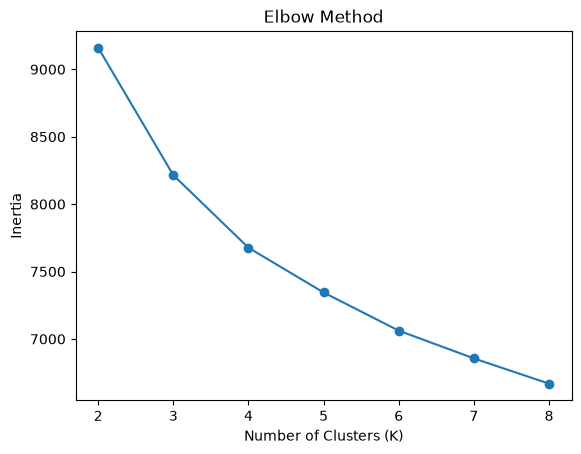

In [22]:
import matplotlib.pyplot as plt

k_values = range(2, 9)

plt.plot(k_values, inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [5]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X)
    score = silhouette_score(X, labels)
    silhouette_scores.append(score)

print(silhouette_scores)

[0.1344846815568261, 0.12056553634949782, 0.10445334141785435, 0.10057501127171233, 0.09948520289175414, 0.0968130563881691, 0.09563982871637162]


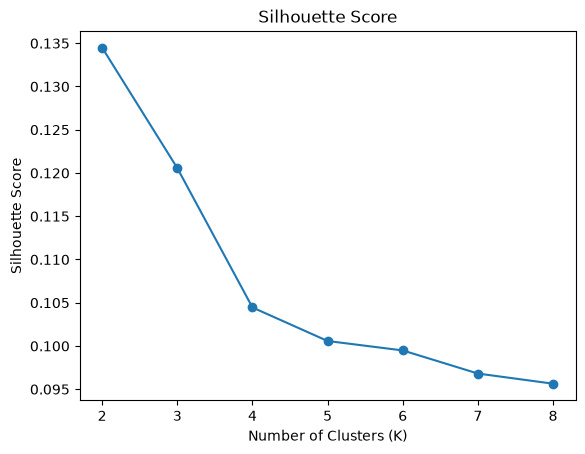

In [6]:
plt.plot(k_values, silhouette_scores, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score")
plt.show()

In [7]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)

clusters = kmeans.fit_predict(X)

df["cluster"] = clusters

print(df["cluster"].value_counts().sort_index())

cluster
0     774
1    1226
Name: count, dtype: int64


In [10]:
cluster_summary = df.groupby("cluster")[[
    "age",
    "satisfaction_score"
]].mean()

print(cluster_summary)

print(pd.crosstab(df["cluster"], df["acquisition_purpose"], normalize="index"))

print("\nLoan behavior:")
print(pd.crosstab(df["cluster"], df["loan_applied"], normalize="index"))

print("\nClient type:")
print(pd.crosstab(df["cluster"], df["client_type"], normalize="index"))

print(pd.crosstab(df["cluster"], df["satisfaction_score"]))

               age  satisfaction_score
cluster                               
0        55.330749            1.489664
1        55.999184            4.000816
acquisition_purpose      Home  Investment
cluster                                  
0                    0.692506    0.307494
1                    0.692496    0.307504

Loan behavior:
loan_applied        No       Yes
cluster                         
0             0.633075  0.366925
1             0.631321  0.368679

Client type:
client_type   Company  Individual
cluster                          
0            0.052972    0.947028
1            0.050571    0.949429
satisfaction_score    1    2    3    4    5
cluster                                    
0                   395  379    0    0    0
1                     0    0  404  417  405


In [11]:
ml_df_no_satisfaction = ml_df.drop(columns=["satisfaction_score"])

print("Shape:", ml_df_no_satisfaction.shape)

Shape: (2000, 8)


In [12]:
categorical_features_no_satisfaction = [
    "client_type",
    "gender",
    "country",
    "region",
    "acquisition_purpose",
    "loan_applied",
    "referral_channel"
]

numerical_features_no_satisfaction = [
    "age"
]

preprocessor_no_satisfaction = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features_no_satisfaction),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features_no_satisfaction)
    ]
)

In [13]:
X_no_satisfaction = preprocessor_no_satisfaction.fit_transform(
    ml_df_no_satisfaction
)

print("Original shape:", ml_df_no_satisfaction.shape)
print("Processed shape:", X_no_satisfaction.shape)

Original shape: (2000, 8)
Processed shape: (2000, 79)


In [14]:
inertia_no_satisfaction = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    model.fit(X_no_satisfaction)
    inertia_no_satisfaction.append(model.inertia_)

print(inertia_no_satisfaction)

[7189.193788049832, 6632.5256098540685, 6194.756964734711, 5890.545961440951, 5713.340158182475, 5455.3750842984555, 5275.261042078315]


In [15]:
silhouette_scores_no_satisfaction = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = model.fit_predict(X_no_satisfaction)
    
    score = silhouette_score(X_no_satisfaction, labels)
    silhouette_scores_no_satisfaction.append(score)

print(silhouette_scores_no_satisfaction)

[0.15325279697782124, 0.12122747523581386, 0.11835225747187855, 0.11296293224905679, 0.12346390812803125, 0.12345588121385248, 0.11673651845236499]


In [18]:
kmeans_no_satisfaction = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

clusters_no_satisfaction = kmeans_no_satisfaction.fit_predict(
    X_no_satisfaction
)

df["cluster_no_satisfaction"] = clusters_no_satisfaction

print(
    df["cluster_no_satisfaction"]
    .value_counts()
    .sort_index()
)

cluster_profile = df.groupby("cluster_no_satisfaction")[["age", "satisfaction_score"]].mean()

print(cluster_profile)

pd.crosstab(
    df["cluster_no_satisfaction"],
    df["acquisition_purpose"],
    normalize="index"
).round(3)

cluster_no_satisfaction
0     975
1    1025
Name: count, dtype: int64
                               age  satisfaction_score
cluster_no_satisfaction                               
0                        40.548718            3.027692
1                        70.191220            3.030244


acquisition_purpose,Home,Investment
cluster_no_satisfaction,,
0,0.659,0.341
1,0.724,0.276


In [19]:
pd.crosstab(
    df["cluster_no_satisfaction"],
    df["loan_applied"],
    normalize="index"
).round(3)

loan_applied,No,Yes
cluster_no_satisfaction,,
0,0.607,0.393
1,0.656,0.344


In [20]:
pd.crosstab(
    df["cluster_no_satisfaction"],
    df["client_type"],
    normalize="index"
).round(3)

client_type,Company,Individual
cluster_no_satisfaction,,
0,0.077,0.923
1,0.027,0.973


In [21]:
pd.crosstab(
    df["cluster_no_satisfaction"],
    df["country"],
    normalize="index"
).round(3)

country,Australia,Belgium,Canada,Denmark,France,Germany,Mexico,Russia,UK,USA
cluster_no_satisfaction,,,,,,,,,,
0,0.022,0.024,0.043,0.009,0.027,0.032,0.019,0.017,0.051,0.756
1,0.018,0.020,0.042,0.006,0.026,0.024,0.020,0.019,0.044,0.781


In [22]:
kmeans_k3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters_k3 = kmeans_k3.fit_predict(X_no_satisfaction)

df["cluster_k3"] = clusters_k3

print(
    df["cluster_k3"]
    .value_counts()
    .sort_index()
)



cluster_k3
0    620
1    749
2    631
Name: count, dtype: int64


In [23]:
# ==============================
# Complete K=3 Cluster Profile
# ==============================

# 1. Cluster size
print("CLUSTER SIZE")
print(df["cluster_k3"].value_counts().sort_index())
print("\n" + "="*60 + "\n")


# 2. Numerical profile
print("AVERAGE AGE & SATISFACTION")
profile = df.groupby("cluster_k3")[[
    "age",
    "satisfaction_score"
]].mean().round(2)

print(profile)
print("\n" + "="*60 + "\n")


# 3. Acquisition purpose
print("ACQUISITION PURPOSE (%)")
purpose = pd.crosstab(
    df["cluster_k3"],
    df["acquisition_purpose"],
    normalize="index"
).round(3) * 100

print(purpose)
print("\n" + "="*60 + "\n")


# 4. Loan behavior
print("LOAN APPLIED (%)")
loan = pd.crosstab(
    df["cluster_k3"],
    df["loan_applied"],
    normalize="index"
).round(3) * 100

print(loan)
print("\n" + "="*60 + "\n")


# 5. Client type
print("CLIENT TYPE (%)")
client_type = pd.crosstab(
    df["cluster_k3"],
    df["client_type"],
    normalize="index"
).round(3) * 100

print(client_type)
print("\n" + "="*60 + "\n")


# 6. Country distribution
print("COUNTRY DISTRIBUTION (%)")
country = pd.crosstab(
    df["cluster_k3"],
    df["country"],
    normalize="index"
).round(3) * 100

print(country)

CLUSTER SIZE
cluster_k3
0    620
1    749
2    631
Name: count, dtype: int64


AVERAGE AGE & SATISFACTION
              age  satisfaction_score
cluster_k3                           
0           66.64                3.02
1           37.06                3.01
2           67.20                3.05


ACQUISITION PURPOSE (%)
acquisition_purpose  Home  Investment
cluster_k3                           
0                    71.0        29.0
1                    65.7        34.3
2                    71.8        28.2


LOAN APPLIED (%)
loan_applied    No   Yes
cluster_k3              
0             64.5  35.5
1             60.1  39.9
2             65.6  34.4


CLIENT TYPE (%)
client_type  Company  Individual
cluster_k3                      
0                3.4        96.6
1                7.9        92.1
2                3.6        96.4


COUNTRY DISTRIBUTION (%)
country     Australia  Belgium  Canada  Denmark  France  Germany  Mexico  \
cluster_k3                                                

## Cluster Selection and Interpretation

Initial K-Means clustering including satisfaction score was strongly influenced by satisfaction levels. A second experiment excluded satisfaction score from the clustering features so that buyer segmentation could focus more on demographic and behavioral characteristics.

The second experiment produced a higher silhouette score for K=2 (0.1533). The resulting clusters showed a clear age-based distinction, with differences also observed in investment purpose, loan application, and client type.

A K=3 experiment produced two very similar older-buyer clusters, making the segmentation less distinct and interpretable. Therefore, K=2 is currently the more interpretable K-Means solution, subject to comparison with hierarchical clustering.


In [24]:
from sklearn.cluster import AgglomerativeClustering
X_no_satisfaction

In [ ]:

X_no_satisfaction_dense = X_no_satisfaction.toarray()

print("Processed data shape:", X_no_satisfaction_dense.shape)


# Create hierarchical clustering model
hierarchical_model = AgglomerativeClustering(
    n_clusters=2
)


# Fit model and get cluster labels
hierarchical_clusters = hierarchical_model.fit_predict(
    X_no_satisfaction_dense
)


# Store cluster labels in dataframe
df["hierarchical_cluster"] = hierarchical_clusters


# Display number of buyers in each cluster
print("\nHierarchical Cluster Size:")
print(
    df["hierarchical_cluster"]
    .value_counts()
    .sort_index()
)

Processed data shape: (2000, 79)

Hierarchical Cluster Size:
hierarchical_cluster
0    1101
1     899
Name: count, dtype: int64


In [ ]:

print("CLUSTER SIZE")
print(
    df["hierarchical_cluster"]
    .value_counts()
    .sort_index()
)

print("\n" + "=" * 60 + "\n")


print("AVERAGE AGE & SATISFACTION")
profile_hierarchical = df.groupby(
    "hierarchical_cluster"
)[["age", "satisfaction_score"]].mean().round(2)

print(profile_hierarchical)

print("\n" + "=" * 60 + "\n")


print("ACQUISITION PURPOSE (%)")
purpose_hierarchical = pd.crosstab(
    df["hierarchical_cluster"],
    df["acquisition_purpose"],
    normalize="index"
).round(3) * 100

print(purpose_hierarchical)

print("\n" + "=" * 60 + "\n")


print("LOAN APPLIED (%)")
loan_hierarchical = pd.crosstab(
    df["hierarchical_cluster"],
    df["loan_applied"],
    normalize="index"
).round(3) * 100

print(loan_hierarchical)

print("\n" + "=" * 60 + "\n")


print("CLIENT TYPE (%)")
client_hierarchical = pd.crosstab(
    df["hierarchical_cluster"],
    df["client_type"],
    normalize="index"
).round(3) * 100

print(client_hierarchical)

print("\n" + "=" * 60 + "\n")


print("COUNTRY DISTRIBUTION (%)")
country_hierarchical = pd.crosstab(
    df["hierarchical_cluster"],
    df["country"],
    normalize="index"
).round(3) * 100

print(country_hierarchical)

CLUSTER SIZE
hierarchical_cluster
0    1101
1     899
Name: count, dtype: int64


AVERAGE AGE & SATISFACTION
                        age  satisfaction_score
hierarchical_cluster                           
0                     67.17                3.03
1                     41.74                3.03


ACQUISITION PURPOSE (%)
acquisition_purpose   Home  Investment
hierarchical_cluster                  
0                     71.8        28.2
1                     66.1        33.9


LOAN APPLIED (%)
loan_applied            No   Yes
hierarchical_cluster            
0                     64.6  35.4
1                     61.5  38.5


CLIENT TYPE (%)
client_type           Company  Individual
hierarchical_cluster                     
0                         0.7        99.3
1                        10.6        89.4


COUNTRY DISTRIBUTION (%)
country               Australia  Belgium  Canada  Denmark  France  Germany  \
hierarchical_cluster                                                       

In [29]:
hierarchical_silhouette = silhouette_score(
    X_no_satisfaction_dense,
    hierarchical_clusters
)

print("Hierarchical Clustering Silhouette Score:")
print(round(hierarchical_silhouette, 4))

Hierarchical Clustering Silhouette Score:
0.1143


In [ ]:


comparison = pd.DataFrame({
    "Method": [
        "K-Means",
        "Hierarchical"
    ],
    "Number of Clusters": [
        2,
        2
    ],
    "Silhouette Score": [
        0.1533,
        0.1143
    ]
})

print(comparison)

         Method  Number of Clusters  Silhouette Score
0       K-Means                   2            0.1533
1  Hierarchical                   2            0.1143


In [ ]:

final_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

final_clusters = final_kmeans.fit_predict(
    X_no_satisfaction
)

df["final_cluster"] = final_clusters

print("Final Cluster Sizes:")
print(
    df["final_cluster"]
    .value_counts()
    .sort_index()
)

Final Cluster Sizes:
final_cluster
0     975
1    1025
Name: count, dtype: int64


In [33]:
final_profile = df.groupby("final_cluster").agg(
    average_age=("age", "mean"),
    average_satisfaction=("satisfaction_score", "mean"),
    buyer_count=("client_id", "count")
)

final_profile

print("Acquisition Purpose:")
print(
    pd.crosstab(
        df["final_cluster"],
        df["acquisition_purpose"],
        normalize="index"
    ).round(3) * 100
)

print("\nLoan Applied:")
print(
    pd.crosstab(
        df["final_cluster"],
        df["loan_applied"],
        normalize="index"
    ).round(3) * 100
)

print("\nClient Type:")
print(
    pd.crosstab(
        df["final_cluster"],
        df["client_type"],
        normalize="index"
    ).round(3) * 100
)

Acquisition Purpose:
acquisition_purpose  Home  Investment
final_cluster                        
0                    65.9        34.1
1                    72.4        27.6

Loan Applied:
loan_applied     No   Yes
final_cluster            
0              60.7  39.3
1              65.6  34.4

Client Type:
client_type    Company  Individual
final_cluster                     
0                  7.7        92.3
1                  2.7        97.3


In [34]:
df.groupby("final_cluster")[["age", "satisfaction_score"]].mean().round(2)

,age,satisfaction_score
final_cluster,,
0,40.55,3.03
1,70.19,3.03


In [ ]:
from sklearn.cluster import KMeans

import matplotlib.pyplot as plt

if "final_cluster" not in df.columns:
    final_kmeans = KMeans(
        n_clusters=2,
        random_state=42,
        n_init=10
    )
    df["final_cluster"] = final_kmeans.fit_predict(X_no_satisfaction)

cluster_counts = df["final_cluster"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(
    [f"Cluster {cluster}" for cluster in cluster_counts.index],
    cluster_counts.values
)

plt.title("Final Buyer Cluster Sizes")
plt.xlabel("Cluster")
plt.ylabel("Number of Buyers")
plt.show()

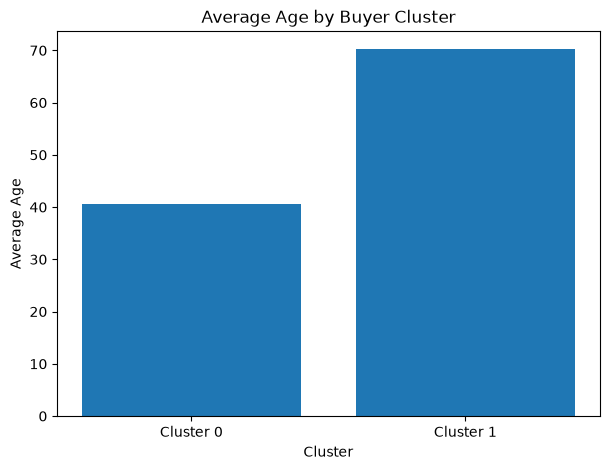

In [36]:
average_age = df.groupby("final_cluster")["age"].mean()

plt.figure(figsize=(7, 5))
plt.bar(
    ["Cluster 0", "Cluster 1"],
    average_age.values
)

plt.title("Average Age by Buyer Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Age")
plt.show()

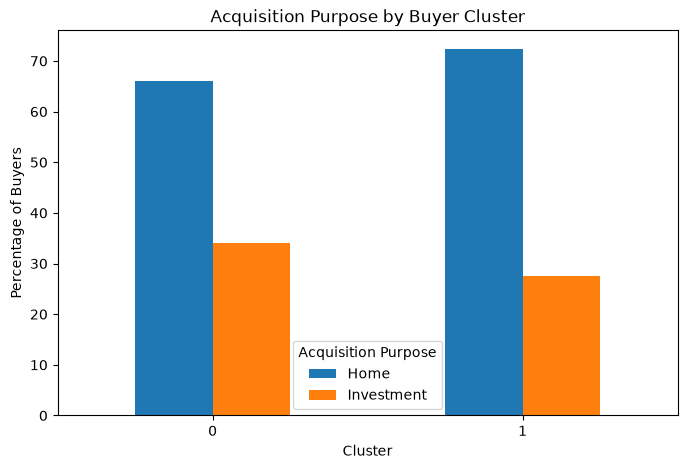

In [37]:
acquisition_table = pd.crosstab(
    df["final_cluster"],
    df["acquisition_purpose"],
    normalize="index"
) * 100

acquisition_table.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Acquisition Purpose by Buyer Cluster")
plt.xlabel("Cluster")
plt.ylabel("Percentage of Buyers")
plt.xticks(rotation=0)
plt.legend(title="Acquisition Purpose")
plt.show()

# Day 2 — Exploratory Data Analysis (EDA) and Business Insights

## Objective

The objective of Day 2 is to explore the real-estate buyer dataset and identify meaningful patterns in buyer demographics, purchasing behavior, financing preferences, satisfaction, geography, and referral channels.

The analysis will help us understand:

- Buyer demographics and age distribution
- Country and regional distribution
- Home vs. investment purchasing behavior
- Loan application behavior
- Individual vs. company buyers
- Customer satisfaction
- Referral channels
- Relationships between important buyer characteristics

## EDA Approach

The analysis will follow these steps:

1. Analyze the overall buyer profile
2. Explore demographic characteristics
3. Analyze geographic distribution
4. Study acquisition purpose
5. Analyze loan behavior
6. Analyze client types
7. Analyze satisfaction scores
8. Analyze referral channels
9. Investigate relationships between important variables
10. Identify key business insights

## Expected Outcome

By the end of Day 2, we will identify the most important patterns in the dataset and convert them into data-supported business insights that can be used later in the research paper and Streamlit dashboard.

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("client.csv")
df.head()



print("Total Buyers:", len(df))

print("\nClient Type:")
print(df["client_type"].value_counts())

print("\nGender:")
print(df["gender"].value_counts())

print("\nAcquisition Purpose:")
print(df["acquisition_purpose"].value_counts())

print("\nLoan Applied:")
print(df["loan_applied"].value_counts())

print("\nReferral Channel:")
print(df["referral_channel"].value_counts())

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("clients.csv")

df.head()

In [ ]:
print("Total Buyers:", len(df))

print("\nClient Type:")
print(df["client_type"].value_counts())

print("\nGender:")
print(df["gender"].value_counts())

print("\nAcquisition Purpose:")
print(df["acquisition_purpose"].value_counts())

print("\nLoan Applied:")
print(df["loan_applied"].value_counts())

print("\nReferral Channel:")
print(df["referral_channel"].value_counts())

In [ ]:
print("Client Type (%):")
print(
    (df["client_type"].value_counts(normalize=True) * 100).round(2)
)

print("\nGender (%):")
print(
    (df["gender"].value_counts(normalize=True) * 100).round(2)
)

print("\nAcquisition Purpose (%):")
print(
    (df["acquisition_purpose"].value_counts(normalize=True) * 100).round(2)
)

print("\nLoan Applied (%):")
print(
    (df["loan_applied"].value_counts(normalize=True) * 100).round(2)
)

print("\nReferral Channel (%):")
print(
    (df["referral_channel"].value_counts(normalize=True) * 100).round(2)
)

In [ ]:
import matplotlib.pyplot as plt

purpose_counts = df["acquisition_purpose"].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    purpose_counts.index,
    purpose_counts.values
)

plt.title("Buyer Acquisition Purpose")
plt.xlabel("Acquisition Purpose")
plt.ylabel("Number of Buyers")

plt.show()

In [ ]:
loan_counts = df["loan_applied"].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    loan_counts.index,
    loan_counts.values
)

plt.title("Buyer Loan Application Status")
plt.xlabel("Loan Applied")
plt.ylabel("Number of Buyers")

plt.show()

In [ ]:
client_type_counts = df["client_type"].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    client_type_counts.index,
    client_type_counts.values
)

plt.title("Buyer Client Type")
plt.xlabel("Client Type")
plt.ylabel("Number of Buyers")

plt.show()

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("clients.csv")

df.head()

,client_id,client_type,first_name,last_name,date_of_birth,gender,country,region,acquisition_purpose,satisfaction_score,loan_applied,referral_channel
0,C0001,Individual,Kareem,Liu,05-11-1968,F,USA,California,Home,4,Yes,Website
1,C0002,Individual,Trystan,Oconnor,11/26/1962,M,USA,California,Home,1,No,Website
2,C0003,Individual,Kale,Gay,04-07-1959,M,USA,California,Home,4,Yes,Agency
3,C0004,Individual,Russell,Gross,11/25/1959,M,USA,California,Home,5,No,Website
4,C0005,Company,Marleez,Co,2/28/1976,M,USA,California,Investment,5,No,Website


In [ ]:
gender_counts = df["gender"].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    gender_counts.index,
    gender_counts.values
)

plt.title("Buyer Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Buyers")

plt.show()

In [ ]:
referral_counts = df["referral_channel"].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    referral_counts.index,
    referral_counts.values
)

plt.title("Buyer Referral Channel Distribution")
plt.xlabel("Referral Channel")
plt.ylabel("Number of Buyers")

plt.show()

In [ ]:
print("Average Age:", df["age"].mean())
print("Median Age:", df["age"].median())
print("Minimum Age:", df["age"].min())
print("Maximum Age:", df["age"].max())

In [ ]:
df["date_of_birth"].head()

In [ ]:
df["date_of_birth"] = pd.to_datetime(
    df["date_of_birth"],
    format="mixed"
)

df["date_of_birth"].head()

In [ ]:
from datetime import datetime

today = pd.Timestamp.today()

df["age"] = (
    today.year
    - df["date_of_birth"].dt.year
    - (
        (today.month < df["date_of_birth"].dt.month)
        |
        (
            (today.month == df["date_of_birth"].dt.month)
            & (today.day < df["date_of_birth"].dt.day)
        )
    )
)

df[["date_of_birth", "age"]].head()

In [ ]:
print("Average Age:", df["age"].mean())
print("Median Age:", df["age"].median())
print("Minimum Age:", df["age"].min())
print("Maximum Age:", df["age"].max())

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["age"],
    bins=10
)

plt.title("Age Distribution of Buyers")
plt.xlabel("Age")
plt.ylabel("Number of Buyers")

plt.show()

In [ ]:
country_counts = df["country"].value_counts()

plt.figure(figsize=(10, 5))

plt.bar(
    country_counts.index,
    country_counts.values
)

plt.title("Buyer Country Distribution")
plt.xlabel("Country")
plt.ylabel("Number of Buyers")

plt.xticks(rotation=45)

plt.show()

In [16]:
region_counts = df["region"].value_counts()
print(region_counts)

region
California                633
Nevada                    143
Colorado                  118
Arizona                   108
Oregon                     96
Utah                       87
Washington                 73
Virginia                   65
Texas                      56
Florida                    50
New York                   49
Georgia                    34
England                    29
Alberta                    27
Scotland                   25
Northern Ireland           24
Ohio                       24
British Columbia           20
Wales                      17
Hamburg                    16
Flanders                   16
Brittany                   16
Ile-de-France              15
Manitoba                   15
Wallonia                   15
Quebec                     14
New South Wales            13
Victoria                   13
Brussels                   12
Bavaria                    12
Berlin                     11
Krasnodar Krai             10
Saint Petersburg           10
Nor

In [ ]:
plt.figure(figsize=(12, 6))

plt.bar(
    region_counts.index,
    region_counts.values
)

plt.title("Buyer Region Distribution")
plt.xlabel("Region")
plt.ylabel("Number of Buyers")

plt.xticks(rotation=90)

plt.show()

In [ ]:
print("Average Satisfaction:", df["satisfaction_score"].mean())
print("Median Satisfaction:", df["satisfaction_score"].median())
print("Minimum Satisfaction:", df["satisfaction_score"].min())
print("Maximum Satisfaction:", df["satisfaction_score"].max())

In [19]:
satisfaction_counts = df["satisfaction_score"].value_counts().sort_index()

print(satisfaction_counts)

satisfaction_score
1    395
2    379
3    404
4    417
5    405
Name: count, dtype: int64


In [ ]:
plt.figure(figsize=(7, 5))

plt.bar(
    satisfaction_counts.index,
    satisfaction_counts.values
)

plt.title("Buyer Satisfaction Score Distribution")
plt.xlabel("Satisfaction Score")
plt.ylabel("Number of Buyers")

plt.show()

In [7]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

labels = kmeans.fit_predict(X)

In [9]:
print("Number of clusters:", kmeans.n_clusters)
print("Model inertia:", round(kmeans.inertia_, 2))

Number of clusters: 2
Model inertia: 9160.31


In [ ]:
inertia_values = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X)
    inertia_values.append(model.inertia_)

    print(f"K = {k}, Inertia = {model.inertia_:.2f}")

In [ ]:
import matplotlib.pyplot as plt

k_values = range(1, 11)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Buyer Segmentation")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [ ]:
from sklearn.metrics import silhouette_score

silhouette_values = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels_k = model.fit_predict(X)
    score = silhouette_score(X, labels_k)

    silhouette_values.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

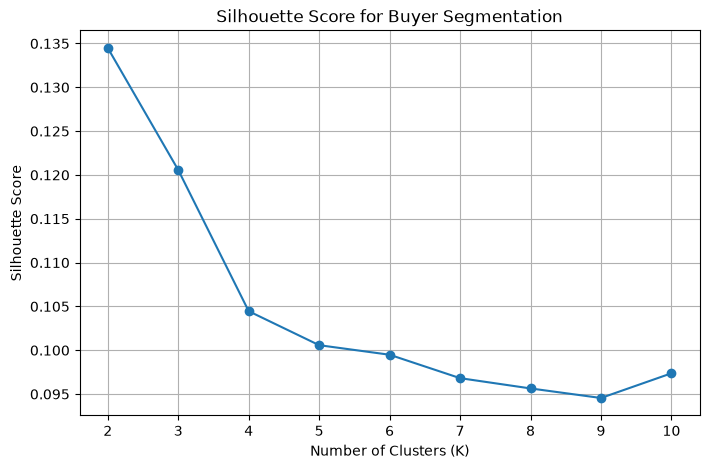

In [13]:
plt.figure(figsize=(8, 5))

k_values = range(2, 11)

plt.plot(
    k_values,
    silhouette_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Buyer Segmentation")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [14]:

profile = df.copy()
profile["cluster"] = labels

cluster_profile = profile.groupby("cluster").agg(
    buyer_count=("client_id", "count"),
    average_age=("age", "mean"),
    average_satisfaction=("satisfaction_score", "mean")
).round(2)

print(cluster_profile)

         buyer_count  average_age  average_satisfaction
cluster                                                
0                774        55.33                  1.49
1               1226        56.00                  4.00


In [16]:
print(df.shape)
print(df.columns.tolist())

(2000, 14)
['client_id', 'client_type', 'first_name', 'last_name', 'date_of_birth', 'gender', 'country', 'region', 'acquisition_purpose', 'satisfaction_score', 'loan_applied', 'referral_channel', 'dob_parsed', 'age']


In [ ]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans

ml_df_no_satisfaction = df.drop(
    columns=[
        "client_id",
        "first_name",
        "last_name",
        "date_of_birth",
        "dob_parsed",
        "satisfaction_score"
    ]
).copy()

numerical_features = ["age"]

categorical_features = [
    "client_type",
    "gender",
    "country",
    "region",
    "acquisition_purpose",
    "loan_applied",
    "referral_channel"
]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

X = preprocessor.fit_transform(ml_df_no_satisfaction)

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

labels = kmeans.fit_predict(X)

ml_df_no_satisfaction["cluster"] = labels

print("Processed feature shape:", X.shape)
print("\nCluster counts:")
print(ml_df_no_satisfaction["cluster"].value_counts().sort_index())

Processed feature shape: (2000, 79)

Cluster counts:
cluster
0     975
1    1025
Name: count, dtype: int64


In [18]:

profile = df.copy()
profile["cluster"] = labels

cluster_profile = profile.groupby("cluster").agg(
    buyer_count=("client_id", "count"),
    average_age=("age", "mean"),
    average_satisfaction=("satisfaction_score", "mean")
).round(2)

print(cluster_profile)

         buyer_count  average_age  average_satisfaction
cluster                                                
0                975        40.55                  3.03
1               1025        70.19                  3.03


In [ ]:
profile = df.copy()
profile["cluster"] = labels

purpose_profile = pd.crosstab(
    profile["cluster"],
    profile["acquisition_purpose"],
    normalize="index"
).mul(100).round(2)

print(purpose_profile)

In [ ]:
loan_profile = pd.crosstab(
    profile["cluster"],
    profile["loan_applied"],
    normalize="index"
).mul(100).round(2)

print(loan_profile)

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

seeds = [0, 21, 42, 99, 123]
results = []

for seed in seeds:
    model = KMeans(
        n_clusters=2,
        random_state=seed,
        n_init=10
    )

    labels_test = model.fit_predict(X)
    score = silhouette_score(X, labels_test)

    results.append({
        "random_seed": seed,
        "inertia": round(model.inertia_, 2),
        "silhouette_score": round(score, 4)
    })

results_df = pd.DataFrame(results)
print(results_df)

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

seeds = [0, 21, 42, 99, 123]
all_labels = {}

for seed in seeds:
    model = KMeans(
        n_clusters=2,
        random_state=seed,
        n_init=10
    )

    labels_test = model.fit_predict(X)
    all_labels[seed] = labels_test

reference_labels = all_labels[42]

for seed in seeds:
    ari = adjusted_rand_score(
        reference_labels,
        all_labels[seed]
    )

    print(f"Seed {seed}: ARI = {ari:.4f}")

In [23]:

age_profile = df.groupby(labels)["age"].agg(
    ["count", "mean", "median", "min", "max"]
)

print(age_profile.round(2))

   count   mean  median  min  max
0    975  40.55    41.0   25   57
1   1025  70.19    70.0   55   95


In [24]:
print("Shape of processed feature matrix:", X.shape)

print("\nNumber of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

print("\nCategorical columns:")
print(categorical_features)

Shape of processed feature matrix: (2000, 79)

Number of numerical features: 1
Number of categorical features: 7

Categorical columns:
['client_type', 'gender', 'country', 'region', 'acquisition_purpose', 'loan_applied', 'referral_channel']


In [25]:
encoder = preprocessor.named_transformers_["cat"]

for feature, categories in zip(
    categorical_features,
    encoder.categories_
):
    print(f"{feature}: {len(categories)} categories")

client_type: 2 categories
gender: 2 categories
country: 10 categories
region: 57 categories
acquisition_purpose: 2 categories
loan_applied: 2 categories
referral_channel: 3 categories


In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

categorical_without_region = [
    feature for feature in categorical_features
    if feature != "region"
]

preprocessor_no_region = ColumnTransformer([
    ("num", StandardScaler(), numerical_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_without_region)
])

X_no_region = preprocessor_no_region.fit_transform(
    ml_df_no_satisfaction[
        numerical_features + categorical_without_region
    ]
)

model_no_region = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

labels_no_region = model_no_region.fit_predict(X_no_region)

score_no_region = silhouette_score(
    X_no_region,
    labels_no_region
)

print("Original feature count:", X.shape[1])
print("Feature count without region:", X_no_region.shape[1])
print("Original silhouette score:", round(
    silhouette_score(X, labels), 4
))
print("Silhouette without region:", round(score_no_region, 4))

Original feature count: 79
Feature count without region: 22
Original silhouette score: 0.1533
Silhouette without region: 0.1926


In [27]:
profile_no_region = df.copy()
profile_no_region["cluster"] = labels_no_region

print(
    profile_no_region.groupby("cluster")["age"]
    .agg(["count", "mean", "median"])
    .round(2)
)

print("\nAcquisition purpose by cluster (%):")
print(
    pd.crosstab(
        profile_no_region["cluster"],
        profile_no_region["acquisition_purpose"],
        normalize="index"
    ).mul(100).round(2)
)

         count   mean  median
cluster                      
0          969  40.45    40.0
1         1031  70.11    70.0

Acquisition purpose by cluster (%):
acquisition_purpose   Home  Investment
cluster                               
0                    66.36       33.64
1                    71.97       28.03


In [28]:
comparison = pd.DataFrame({
    "Model": [
        "Original (with region)",
        "Without region"
    ],
    "Features": [
        X.shape[1],
        X_no_region.shape[1]
    ],
    "Silhouette Score": [
        silhouette_score(X, labels),
        silhouette_score(X_no_region, labels_no_region)
    ]
})

print(comparison.round(4))

                    Model  Features  Silhouette Score
0  Original (with region)        79            0.1533
1          Without region        22            0.1926


In [2]:
print("X_no_region exists:", "X_no_region" in globals())
print("ml_df_no_satisfaction exists:", "ml_df_no_satisfaction" in globals())
print("categorical_features exists:", "categorical_features" in globals())
print("numerical_features exists:", "numerical_features" in globals())

X_no_region exists: False
ml_df_no_satisfaction exists: False
categorical_features exists: False
numerical_features exists: False


In [5]:
import pandas as pd
import numpy as np

df = pd.read_csv("clients.csv")

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (2000, 12)
  client_id client_type first_name last_name date_of_birth gender country  \
0     C0001  Individual     Kareem       Liu    05-11-1968      F     USA   
1     C0002  Individual    Trystan   Oconnor    11/26/1962      M     USA   
2     C0003  Individual       Kale       Gay    04-07-1959      M     USA   
3     C0004  Individual    Russell     Gross    11/25/1959      M     USA   
4     C0005     Company    Marleez        Co     2/28/1976      M     USA   

       region acquisition_purpose  satisfaction_score loan_applied  \
0  California                Home                   4          Yes   
1  California                Home                   1           No   
2  California                Home                   4          Yes   
3  California                Home                   5           No   
4  California          Investment                   5           No   

  referral_channel  
0          Website  
1          Website  
2           Agency  
3     

In [ ]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Parse dates with mixed formats
df["date_of_birth"] = pd.to_datetime(
    df["date_of_birth"],
    format="mixed"
)

# Calculate age
today = pd.Timestamp.today()

df["age"] = (
    today.year
    - df["date_of_birth"].dt.year
    - (
        (today.month < df["date_of_birth"].dt.month)
        | (
            (today.month == df["date_of_birth"].dt.month)
            & (today.day < df["date_of_birth"].dt.day)
        )
    )
)

# Featuresaf
numerical_features = ["age"]

categorical_features = [
    "client_type",
    "gender",
    "country",
    "region",
    "acquisition_purpose",
    "loan_applied",
    "referral_channel"
]

# Exclude IDs, names, dates,
ml_df_no_satisfaction = df.drop(
    columns=[
        "client_id",
        "first_name",
        "last_name",
        "date_of_birth",
        "satisfaction_score"
    ]
).copy()

print("Dataset shape:", df.shape)
print("Features ready:", numerical_features + categorical_features)
print("Missing ages:", df["age"].isna().sum())

Dataset shape: (2000, 13)
Features ready: ['age', 'client_type', 'gender', 'country', 'region', 'acquisition_purpose', 'loan_applied', 'referral_channel']
Missing ages: 0


In [7]:
categorical_without_region = [
    feature for feature in categorical_features
    if feature != "region"
]

preprocessor_no_region = ColumnTransformer([
    ("num", StandardScaler(), numerical_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_without_region)
])

X_no_region = preprocessor_no_region.fit_transform(
    ml_df_no_satisfaction[
        numerical_features + categorical_without_region
    ]
)

print("Feature matrix shape:", X_no_region.shape)
print("Categorical features:", categorical_without_region)

Feature matrix shape: (2000, 22)
Categorical features: ['client_type', 'gender', 'country', 'acquisition_purpose', 'loan_applied', 'referral_channel']


In [8]:
k_results = []

for k in [2, 3, 4, 5]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels_test = model.fit_predict(X_no_region)

    score = silhouette_score(
        X_no_region,
        labels_test
    )

    k_results.append({
        "K": k,
        "Inertia": round(model.inertia_, 2),
        "Silhouette Score": round(score, 4)
    })

k_results_df = pd.DataFrame(k_results)
print(k_results_df)

   K  Inertia  Silhouette Score
0  2  5434.20            0.1928
1  3  4878.39            0.1626
2  4  4442.25            0.1637
3  5  4151.92            0.1656


In [9]:
stability_results = []

for seed in [0, 21, 42, 99, 123]:
    model = KMeans(
        n_clusters=2,
        random_state=seed,
        n_init=10
    )

    labels_test = model.fit_predict(X_no_region)

    stability_results.append({
        "seed": seed,
        "inertia": round(model.inertia_, 2),
        "silhouette": round(
            silhouette_score(X_no_region, labels_test), 4
        )
    })

print(pd.DataFrame(stability_results))

   seed  inertia  silhouette
0     0  5434.20      0.1929
1    21  5434.19      0.1928
2    42  5434.20      0.1928
3    99  5434.20      0.1928
4   123  5434.18      0.1928


In [ ]:
final_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

final_labels = final_kmeans.fit_predict(X_no_region)

cluster_counts = pd.Series(
    final_labels,
    name="cluster"
).value_counts().sort_index()

print("Cluster counts:")
print(cluster_counts)

print("\nCluster percentages:")
print(
    (cluster_counts / len(final_labels) * 100).round(2)
)

In [11]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Agglomerative Clustering
agg_model = AgglomerativeClustering(n_clusters=2)

agg_labels = agg_model.fit_predict(X_no_region)

# Evaluate its clustering
agg_score = silhouette_score(
    X_no_region,
    agg_labels
)

# Compare against your Day 8 K-Means result
kmeans_score = silhouette_score(
    X_no_region,
    final_labels
)

print("K-Means silhouette score:", round(kmeans_score, 4))
print("Agglomerative silhouette score:", round(agg_score, 4))

K-Means silhouette score: 0.1928
Agglomerative silhouette score: 0.1566


In [12]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

linkage_results = []

for method in ["ward", "average"]:
    model = AgglomerativeClustering(
        n_clusters=2,
        linkage=method
    )

    labels_test = model.fit_predict(X_no_region)

    score = silhouette_score(
        X_no_region,
        labels_test
    )

    linkage_results.append({
        "Linkage": method,
        "Silhouette Score": round(score, 4)
    })

print(pd.DataFrame(linkage_results))

   Linkage  Silhouette Score
0     ward            0.1566
1  average            0.1845


In [13]:
from sklearn.metrics import adjusted_rand_score

average_model = AgglomerativeClustering(
    n_clusters=2,
    linkage="average"
)

average_labels = average_model.fit_predict(X_no_region)

ari_average = adjusted_rand_score(
    final_labels,
    average_labels
)

print("ARI between K-Means and Average linkage:",
      round(ari_average, 4))

ARI between K-Means and Average linkage: -0.0001


In [14]:
import pandas as pd

print("K-Means cluster sizes:")
print(pd.Series(final_labels).value_counts().sort_index())

print("\nAgglomerative Average cluster sizes:")
print(pd.Series(average_labels).value_counts().sort_index())

K-Means cluster sizes:
0    1030
1     970
Name: count, dtype: int64

Agglomerative Average cluster sizes:
0    1999
1       1
Name: count, dtype: int64


In [15]:
ward_model = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)

ward_labels = ward_model.fit_predict(X_no_region)

print("Ward cluster sizes:")
print(pd.Series(ward_labels).value_counts().sort_index())

Ward cluster sizes:
0     938
1    1062
Name: count, dtype: int64


In [16]:
from sklearn.metrics import adjusted_rand_score

ari_ward = adjusted_rand_score(final_labels, ward_labels)

print("ARI between K-Means and Ward:", round(ari_ward, 4))

ARI between K-Means and Ward: 0.4982


In [17]:
profile_df = df.copy()
profile_df["cluster"] = final_labels

print(
    profile_df.groupby("cluster").agg(
        buyer_count=("client_id", "count"),
        average_age=("age", "mean"),
        average_satisfaction=("satisfaction_score", "mean")
    ).round(2)
)

         buyer_count  average_age  average_satisfaction
cluster                                                
0               1030        70.32                  3.03
1                970        40.64                  3.03


In [18]:
purpose_profile = pd.crosstab(
    profile_df["cluster"],
    profile_df["acquisition_purpose"],
    normalize="index"
) * 100

print(purpose_profile.round(2))

acquisition_purpose   Home  Investment
cluster                               
0                    72.23       27.77
1                    66.08       33.92


In [19]:
print("Dataset shape:", X_no_region.shape)
print("Number of clusters:", len(set(final_labels)))
print("Silhouette score:", round(
    silhouette_score(X_no_region, final_labels), 4
))

print("\nCluster sizes:")
print(pd.Series(final_labels).value_counts().sort_index())

Dataset shape: (2000, 22)
Number of clusters: 2
Silhouette score: 0.1928

Cluster sizes:
0    1030
1     970
Name: count, dtype: int64


In [20]:
final_profile = profile_df.groupby("cluster").agg(
    buyer_count=("client_id", "count"),
    average_age=("age", "mean"),
    average_satisfaction=("satisfaction_score", "mean")
).round(2)

final_profile["buyer_percentage"] = (
    final_profile["buyer_count"] / len(profile_df) * 100
).round(2)

print(final_profile)

         buyer_count  average_age  average_satisfaction  buyer_percentage
cluster                                                                  
0               1030        70.32                  3.03              51.5
1                970        40.64                  3.03              48.5
